# 06 — Model B evaluation and fair development comparison

This notebook compares the frozen embedding baseline (Model A) and the fine-tuned ResNet-18 (Model B) on exactly the same internal-validation studies. It is a development comparison only. The official MURA valid split is not read or used for a new decision.

In [1]:
import json
import os
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)

## Load internal-validation predictions

In [2]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ModuleNotFoundError:
    pass

DATA_DIR = Path(os.environ.get("MURA_DATA_DIR", "/content/drive/MyDrive/DATA"))
PROJECT_ROOT = Path(os.environ.get(
    "MURA_PROJECT_ROOT",
    "/content/drive/MyDrive/MURA_PROJECT/mura-wrist-ml-pipeline",
))
MODEL_A_DIR = DATA_DIR / "BASELINE_MODEL_A"
MODEL_B_DIR = Path(os.environ.get("MURA_MODEL_B_DIR", str(DATA_DIR / "MODEL_B_FINE_TUNING")))
OUTPUT_DIR = DATA_DIR / "MODEL_A_MODEL_B_COMPARISON"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

verification = subprocess.run(
    [
        sys.executable,
        str(PROJECT_ROOT / "scripts" / "verify_model_artifact_bundle.py"),
        "--artifact-dir", str(MODEL_B_DIR),
        "--bundle-spec", str(PROJECT_ROOT / "configs" / "model_b_artifact_bundle.json"),
    ],
    check=True, capture_output=True, text=True,
)
model_b_bundle = json.loads(verification.stdout)
print({
    "model_b_bundle_verified": True,
    "selected_threshold": model_b_bundle["threshold"],
    "target_sensitivity": model_b_bundle["target_sensitivity"],
    "checkpoint_sha256_prefix": model_b_bundle["checkpoint_sha256"][:12],
})

model_a = pd.read_csv(MODEL_A_DIR / "validation_predictions.csv")
model_b = pd.read_csv(MODEL_B_DIR / "validation_predictions.csv")
model_a = model_a.rename(columns={"abnormal_probability": "model_a_probability"})
model_b = model_b.rename(columns={"abnormal_probability": "model_b_probability"})

common = model_a.merge(
    model_b[["patient_id", "study_id", "label", "num_views", "model_b_probability"]],
    on=["patient_id", "study_id", "label", "num_views"],
    how="inner",
    validate="one_to_one",
)
assert len(common) == len(model_a) == len(model_b)
assert common["study_id"].is_unique
assert common["label"].isin([0, 1]).all()
display(pd.DataFrame([{
    'validation_studies': len(common),
    'validation_patients': common['patient_id'].nunique(),
    'normal_studies': int((common['label'] == 0).sum()),
    'abnormal_studies': int((common['label'] == 1).sum()),
}]))

{'model_b_bundle_verified': True, 'selected_threshold': 0.263567715883255, 'target_sensitivity': 0.95, 'checkpoint_sha256_prefix': '63AEDC6BEC15'}


,validation_studies,validation_patients,normal_studies,abnormal_studies
0,691,653,422,269


## Ranking metrics

In [3]:
def ranking_metrics(labels, scores):
    return {
        "AUROC": float(roc_auc_score(labels, scores)),
        "AUPRC": float(average_precision_score(labels, scores)),
    }

ranking = pd.DataFrame([
    {"model": "Model A: frozen embeddings plus Logistic Regression", **ranking_metrics(common["label"], common["model_a_probability"])},
    {"model": "Model B: fine-tuned ResNet-18", **ranking_metrics(common["label"], common["model_b_probability"])},
])
display(ranking)

,model,AUROC,AUPRC
0,Model A: frozen embeddings plus Logistic Regre...,0.880442,0.851514
1,Model B: fine-tuned ResNet-18,0.912807,0.878133


## Sensitivity-constrained operating policy

In [4]:
PRIMARY_SENSITIVITY_TARGET = 0.95

def metrics_at_threshold(labels, scores, threshold):
    predicted = (np.asarray(scores) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, predicted, labels=[0, 1]).ravel()
    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    return {
        "threshold": float(threshold),
        "sensitivity": float(sensitivity),
        "specificity": float(specificity),
        "precision": float(precision_score(labels, predicted, zero_division=0)),
        "f1": float(f1_score(labels, predicted, zero_division=0)),
        "false_negative": int(fn),
        "false_positive": int(fp),
        "flagged_percent": float(100 * predicted.mean()),
        "youden_j": float(sensitivity + specificity - 1),
    }

def make_threshold_table(labels, scores):
    thresholds = np.unique(np.append(np.asarray(scores, dtype=float), 0.50))[::-1]
    return pd.DataFrame([metrics_at_threshold(labels, scores, threshold) for threshold in thresholds])

def select_policy(table, target):
    eligible = table.loc[table["sensitivity"] >= target].copy()
    if eligible.empty:
        raise RuntimeError(f"No threshold achieved sensitivity >= {target:.0%}")
    return eligible.sort_values(["threshold", "specificity"], ascending=[False, False]).iloc[0].to_dict()

policies = []
threshold_tables = {}
for model_name, score_column in [
    ("Model A: frozen embeddings plus Logistic Regression", "model_a_probability"),
    ("Model B: fine-tuned ResNet-18", "model_b_probability"),
]:
    table = make_threshold_table(common["label"], common[score_column])
    threshold_tables[score_column] = table
    chosen = select_policy(table, PRIMARY_SENSITIVITY_TARGET)
    policies.append({"model": model_name, "policy": f"sensitivity >= {PRIMARY_SENSITIVITY_TARGET:.0%}", **chosen})
    table.to_csv(OUTPUT_DIR / f"{score_column}_threshold_table.csv", index=False)

operating_points = pd.DataFrame(policies)
display(operating_points)

,model,policy,threshold,sensitivity,specificity,precision,f1,false_negative,false_positive,flagged_percent,youden_j
0,Model A: frozen embeddings plus Logistic Regre...,sensitivity >= 95%,0.063773,0.951673,0.393365,0.500000,0.655570,13.0,256.0,74.095514,0.345038
1,Model B: fine-tuned ResNet-18,sensitivity >= 95%,0.263568,0.951673,0.582938,0.592593,0.730385,13.0,176.0,62.518090,0.534611


## Patient-cluster bootstrap interval

In [5]:
def bootstrap_interval(frame, score_column, threshold, seed=42, iterations=1000):
    # Resample patient clusters. Integer study weights exactly represent drawing
    # a patient more than once, without repeatedly copying the same rows.
    rng = np.random.default_rng(seed)
    patient_codes, _ = pd.factorize(frame["patient_id"].astype(str), sort=False)
    labels = frame["label"].to_numpy(dtype=int)
    scores = frame[score_column].to_numpy(dtype=float)
    samples = []
    for _ in range(iterations):
        drawn = rng.integers(0, patient_codes.max() + 1, size=patient_codes.max() + 1)
        weights_by_patient = np.bincount(drawn, minlength=patient_codes.max() + 1)
        sample_weight = weights_by_patient[patient_codes]
        if not np.any(sample_weight[labels == 0]) or not np.any(sample_weight[labels == 1]):
            continue
        predicted = scores >= threshold
        tn = sample_weight[(labels == 0) & ~predicted].sum()
        fp = sample_weight[(labels == 0) & predicted].sum()
        fn = sample_weight[(labels == 1) & ~predicted].sum()
        tp = sample_weight[(labels == 1) & predicted].sum()
        samples.append({
            "AUROC": roc_auc_score(labels, scores, sample_weight=sample_weight),
            "AUPRC": average_precision_score(labels, scores, sample_weight=sample_weight),
            "sensitivity": tp / (tp + fn),
            "specificity": tn / (tn + fp),
        })
    samples = pd.DataFrame(samples)
    return {
        metric: (
            float(samples[metric].quantile(0.025)),
            float(samples[metric].quantile(0.975)),
        )
        for metric in samples.columns
    }

bootstrap_rows = []
for _, policy in operating_points.iterrows():
    score_column = "model_a_probability" if policy["model"].startswith("Model A") else "model_b_probability"
    intervals = bootstrap_interval(common, score_column, policy["threshold"])
    bootstrap_rows.append({
        "model": policy["model"],
        "AUROC_95_CI": intervals["AUROC"],
        "AUPRC_95_CI": intervals["AUPRC"],
        "sensitivity_95_CI": intervals["sensitivity"],
        "specificity_95_CI": intervals["specificity"],
    })
bootstrap_summary = pd.DataFrame(bootstrap_rows)
display(bootstrap_summary)

,model,AUROC_95_CI,AUPRC_95_CI,sensitivity_95_CI,specificity_95_CI
0,Model A: frozen embeddings plus Logistic Regre...,"(0.8538469222373447, 0.9065013805694961)","(0.8121398659314607, 0.8886195942657475)","(0.9269910315170033, 0.9743659420289855)","(0.3491686460807601, 0.4414094320008634)"
1,Model B: fine-tuned ResNet-18,"(0.8886668958733625, 0.934904240211305)","(0.8316970716830333, 0.9164099115593488)","(0.9243012797295665, 0.9761904761904762)","(0.5362275292642141, 0.6279773188896411)"


## Curves and workload comparison

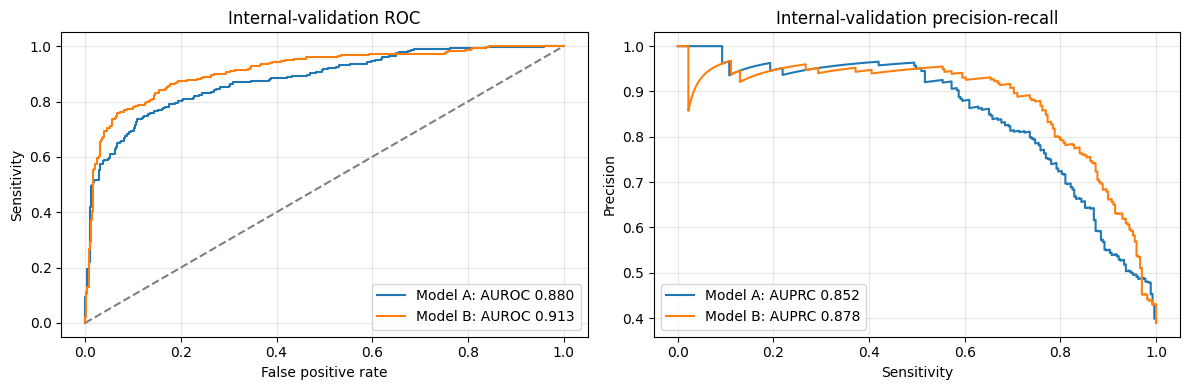

,model,threshold,sensitivity,specificity,precision,false_negative,false_positive,flagged_percent
0,Model A: frozen embeddings plus Logistic Regre...,0.063773,0.951673,0.393365,0.500000,13.0,256.0,74.095514
1,Model B: fine-tuned ResNet-18,0.263568,0.951673,0.582938,0.592593,13.0,176.0,62.518090


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for model_name, score_column, color in [
    ("Model A", "model_a_probability", "tab:blue"),
    ("Model B", "model_b_probability", "tab:orange"),
]:
    fpr, tpr, _ = roc_curve(common["label"], common[score_column])
    precision, recall, _ = precision_recall_curve(common["label"], common[score_column])
    axes[0].plot(fpr, tpr, color=color, label=f"{model_name}: AUROC {roc_auc_score(common['label'], common[score_column]):.3f}")
    axes[1].plot(recall, precision, color=color, label=f"{model_name}: AUPRC {average_precision_score(common['label'], common[score_column]):.3f}")

axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(xlabel="False positive rate", ylabel="Sensitivity", title="Internal-validation ROC")
axes[1].set(xlabel="Sensitivity", ylabel="Precision", title="Internal-validation precision-recall")
for axis in axes:
    axis.legend()
    axis.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(operating_points[["model", "threshold", "sensitivity", "specificity", "precision", "false_negative", "false_positive", "flagged_percent"]])

## Save development-only comparison

The 95% sensitivity target is fixed before comparing the models. Each model receives its own threshold, selected only from its study-level internal-validation probabilities.


In [7]:
comparison = ranking.merge(
    operating_points[["model", "threshold", "sensitivity", "specificity", "precision", "f1", "false_negative", "false_positive", "flagged_percent"]],
    on="model",
    how="left",
)
comparison.to_csv(OUTPUT_DIR / "internal_validation_model_comparison.csv", index=False)
bootstrap_summary.to_csv(OUTPUT_DIR / "internal_validation_bootstrap_intervals.csv", index=False)

policy_paths = {
    "Model A: frozen embeddings plus Logistic Regression": (MODEL_A_DIR / "frozen_primary_operating_policy.json", "mean_embedding"),
    "Model B: fine-tuned ResNet-18": (MODEL_B_DIR / "frozen_primary_operating_policy.json", "mean_probability"),
}
for _, row in operating_points.iterrows():
    policy_path, aggregation = policy_paths[row["model"]]
    policy_payload = {
        "model": row["model"],
        "study_aggregation": aggregation,
        "source_split": "internal_validation",
        "selection_rule": "highest threshold with sensitivity >= target",
        "target_sensitivity": float(PRIMARY_SENSITIVITY_TARGET),
        "test_used_for_selection": False,
        **{
            key: (int(row[key]) if key in {"false_negative", "false_positive"} else float(row[key]))
            for key in ["threshold", "sensitivity", "specificity", "precision", "f1", "false_negative", "false_positive", "flagged_percent"]
        },
    }
    policy_path.write_text(json.dumps(policy_payload, indent=2), encoding="utf-8")

(OUTPUT_DIR / "governance.json").write_text(json.dumps({
    "split": "internal_validation",
    "official_mura_valid_read": False,
    "threshold_selection": f"highest threshold with sensitivity >= {PRIMARY_SENSITIVITY_TARGET:.0%} on internal validation",
    "limitation": "These are development estimates. The same internal validation split supports early stopping and operating policy selection.",
}, indent=2), encoding="utf-8")
display(comparison)


,model,AUROC,AUPRC,threshold,sensitivity,specificity,precision,f1,false_negative,false_positive,flagged_percent
0,Model A: frozen embeddings plus Logistic Regre...,0.880442,0.851514,0.063773,0.951673,0.393365,0.500000,0.655570,13.0,256.0,74.095514
1,Model B: fine-tuned ResNet-18,0.912807,0.878133,0.263568,0.951673,0.582938,0.592593,0.730385,13.0,176.0,62.518090


## Interpretation boundary

Both models are compared fairly because they predict the same studies. This is still not a new untouched final-test comparison, and it does not establish clinical deployment readiness.